# 05 · Virtual power plant: bidding for regulation and splitting the signal in microseconds

**Where this sits in the chain:** process model → parameter identification → dimension reduction → *grid/aggregator optimization*.

A virtual power plant (VPP) pools many small, different resources (EVs, storage, air conditioning, industrial production stages, PV) and sells **energy** and **frequency regulation** in the market. It decides on two time scales:

1. **Bidding (every 30 min).** An LP over the rest of the day chooses hourly energy and regulation bids. The regulation signal is uncertain, so the LP plans every resource's power under signal scenarios $d_s \in [-1, 1]$ with their probabilities.
2. **Disaggregation (every 2 s).** The grid operator sends a signal $\delta$, and the VPP must deliver $P^{\rm req} = P^{\rm bid} + R^{\rm bid}\,\delta$ immediately, split among its resources. Re-solving an optimization every 2 s is too slow. The trick: the bidding LP's **dual variables** $\lambda_i$ (the value of the energy stored in resource $i$) give every resource a constant marginal cost. Sorting resources by that cost gives a **merit order**, and filling it up to $P^{\rm req}$ solves the split exactly.

*Reference:* Q. Chen, R. Lyu, H. Guo, X. Su, "Real-Time Operation Strategy of Virtual Power Plants With Optimal Power Disaggregation Among Heterogeneous Resources," *Applied Energy* 361 (2024) 122876; thesis Ch. 5; paper code: [Real-time-operation-strategy-of-virtual-power-plants](https://github.com/ruikelyu/Real-time-operation-strategy-of-virtual-power-plants).

Everything here runs with the free HiGHS solver.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ruikelyu/indflex/blob/main/notebooks/05_vpp.ipynb)

In [1]:
# On Google Colab, install indflex first (locally: pip install -e ".[dev]")
import sys
if "google.colab" in sys.modules:
    !pip install -q "indflex[dev] @ git+https://github.com/ruikelyu/indflex"

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from indflex.coordinate import load_vpp_case, bid, merit_order, allocate, allocate_lp, simulate_hour

plt.rcParams["figure.dpi"] = 110
KINDS = ["EV", "ES", "TCL", "IPP", "PV"]
COLORS = {"EV": "tab:blue", "ES": "tab:purple", "TCL": "tab:green", "IPP": "tab:orange", "PV": "gold"}
LABELS = {"EV": "EVs", "ES": "storage", "TCL": "air conditioning", "IPP": "industrial stages", "PV": "PV"}

## 1. The resources

One day of the paper's case (PJM prices and RegD signal). Every resource uses the same *standardized model*: discharge and charge power limits, an energy state with self-loss and efficiencies, external drift (heat gains for air conditioning), and usage costs. For industrial stages, the "energy" is the material in the buffer after the stage: running stage $i$ fills its buffer and drains the one before it.

VPP of the Applied Energy paper (Chen, Lyu et al., 2024), day 21: 1 PV, 1 storage, 120 EVs, 3 air-conditioning loads (TCL), 10 industrial stages (IPP)


,count
EV,120
IPP,10
TCL,3
PV,1
ES,1


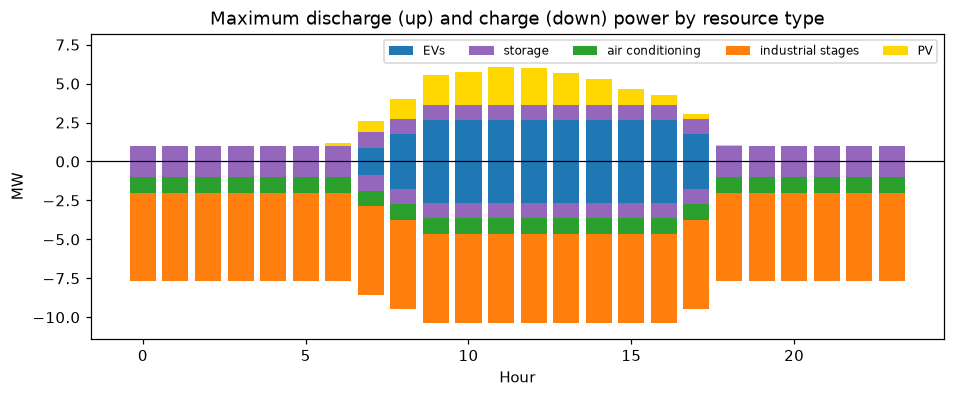

In [3]:
case = load_vpp_case("day21")
kind = np.array(case.kind)
print(case.description)
display(pd.Series(kind).value_counts().rename("count").to_frame())

hours = np.arange(case.T)
fig, ax = plt.subplots(figsize=(10, 3.6))
up, down = np.zeros(case.T), np.zeros(case.T)
for k in KINDS:
    dis = case.p_dis_upper[kind == k].sum(axis=0)
    ch = case.p_ch_upper[kind == k].sum(axis=0)
    ax.bar(hours, dis, bottom=up, color=COLORS[k], label=LABELS[k]); up += dis
    ax.bar(hours, -ch, bottom=-down, color=COLORS[k]); down += ch
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Hour", ylabel="MW", title="Maximum discharge (up) and charge (down) power by resource type")
ax.set_ylim(-down.max() * 1.1, up.max() * 1.35)
ax.legend(fontsize=8, ncol=5); plt.show()

## 2. Bidding: one LP for the day

The LP maximizes energy revenue plus regulation capacity and mileage revenue, minus usage costs, over 22 signal scenarios. It keeps every resource within its limits in every scenario, and keeps enough stored energy to sustain the full signal for 30 minutes.

solved in 3.8 s, expected profit $3,307


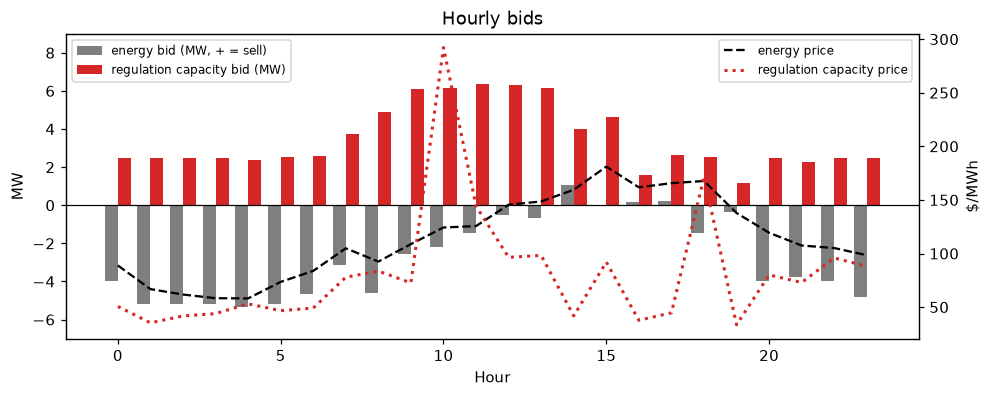

In [4]:
day_ahead = bid(case)
print(f"solved in {day_ahead.seconds:.1f} s, expected profit ${day_ahead.profit:,.0f}")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(hours - 0.2, day_ahead.bid_p, width=0.4, color="tab:gray", label="energy bid (MW, + = sell)")
ax.bar(hours + 0.2, day_ahead.bid_r, width=0.4, color="tab:red", label="regulation capacity bid (MW)")
ax.axhline(0, color="black", lw=0.8); ax.set(xlabel="Hour", ylabel="MW", ylim=(-7, 9)); ax.legend(fontsize=8, loc="upper left")
ax2 = ax.twinx()
ax2.plot(hours, case.price_e, "k--", lw=1.5, label="energy price")
ax2.plot(hours, case.price_reg[:, 0], ":", color="tab:red", lw=2, label="regulation capacity price")
ax2.set_ylabel("$/MWh"); ax2.legend(fontsize=8, loc="upper right")
plt.title("Hourly bids"); plt.show()

The VPP buys energy (negative bids) mainly to charge EVs, and sells regulation capacity in every hour.

## 3. From duals to a merit order

At the start of each half hour the VPP re-solves the bidding LP from its current state. The dual of "energy now = measured energy" is $\lambda_i = \partial\,\text{profit}/\partial E_i$, the value of one more unit stored in resource $i$. With it, every resource becomes two **power segments** with constant marginal costs:

* discharging: usage cost $+$ the value of the stored energy it uses;
* charging (negative power): $-$usage cost $+$ the value of the energy it stores.

Sorted by cost, the segments form a supply curve. Following the signal means moving along this curve. In hour 1 (midnight) no EVs are connected yet, so air conditioning, storage and the industrial stages provide the flexibility.

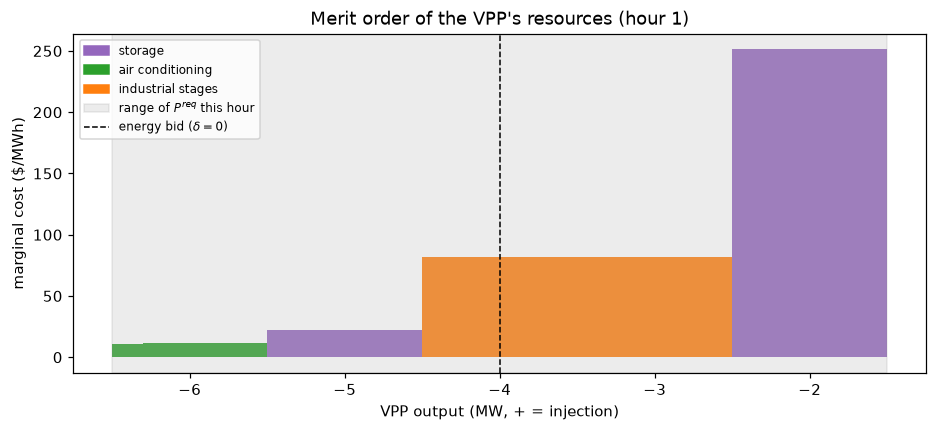

In [5]:
rebid = bid(case, cur_slot=0, E_cur=case.energy_init, bid_cur=(day_ahead.bid_p[0], day_ahead.bid_r[0]), rest=1.0)
seg = merit_order(case, rebid.lam, case.energy_init, slot=0, p_none_reg=rebid.p_none_reg)

base = seg.p_lo.sum()  # every segment at its lower bound
x = base + np.r_[0, np.cumsum(seg.p_hi - seg.p_lo)]
fig, ax = plt.subplots(figsize=(10, 4))
for k in range(len(seg.cost)):
    if seg.p_hi[k] - seg.p_lo[k] > 1e-9:
        ax.fill_between([x[k], x[k + 1]], 0, seg.cost[k], step="pre", color=COLORS[kind[seg.der[k]]], alpha=0.85, lw=0)
for k in KINDS:  # legend only for types with flexible power this hour
    if any((kind[seg.der] == k) & (seg.p_hi - seg.p_lo > 1e-9)):
        ax.fill_between([], [], color=COLORS[k], label=LABELS[k])
bp, br = day_ahead.bid_p[0], day_ahead.bid_r[0]
ax.axvspan(bp - br, bp + br, color="grey", alpha=0.15, label="range of $P^{req}$ this hour")
ax.axvline(bp, color="black", ls="--", lw=1, label="energy bid ($\\delta = 0$)")
ax.set(xlabel="VPP output (MW, + = injection)", ylabel="marginal cost ($/MWh)",
       title="Merit order of the VPP's resources (hour 1)")
ax.legend(fontsize=8, loc="upper left"); plt.show()

## 4. Following the regulation signal for one hour

Every 2 s: $P^{\rm req} = P^{\rm bid} + R^{\rm bid}\delta$, filled along the merit order. Every minute the merit order is rebuilt from the updated energy states. (The paper also re-bids every 30 minutes; for clarity this hour uses one re-bid.)

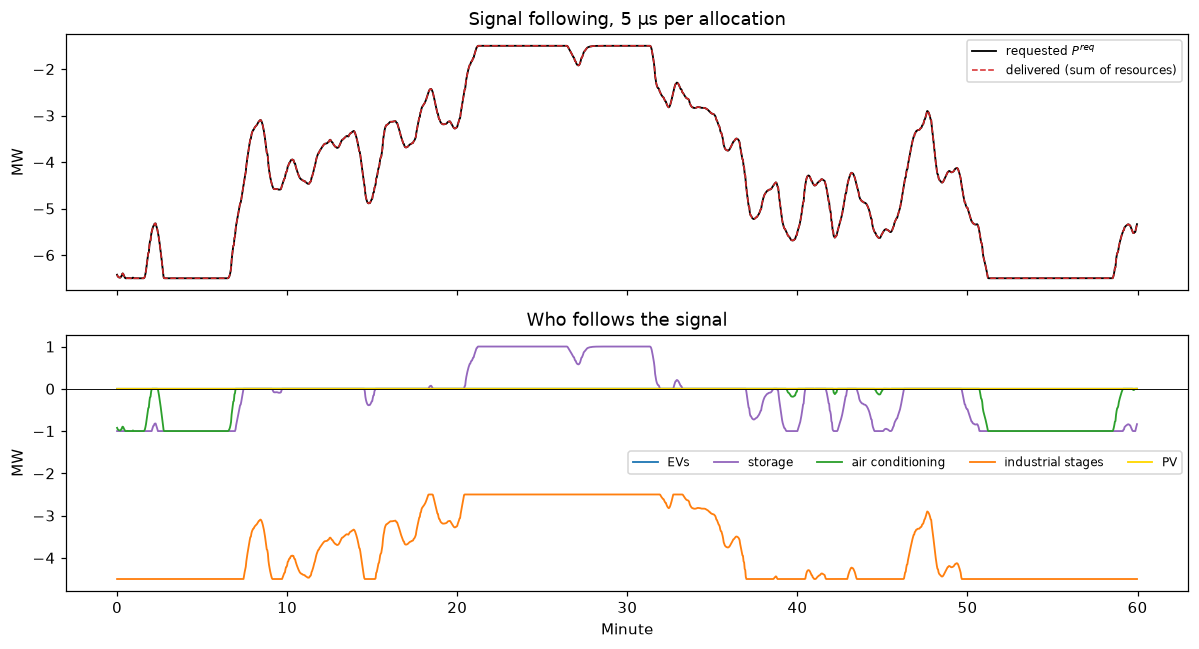

In [6]:
hour = simulate_hour(case, 0, bp, br, rebid.lam, case.energy_init, rebid.p_none_reg)
net = hour.p_dis - hour.p_ch
t_min = np.arange(len(hour.p_req)) * 2 / 60

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(t_min, hour.p_req, color="black", lw=1.2, label="requested $P^{req}$")
axes[0].plot(t_min, net.sum(axis=0), "--", color="tab:red", lw=1, label="delivered (sum of resources)")
axes[0].set(ylabel="MW", title=f"Signal following, {1e6 * hour.alloc_seconds:.0f} µs per allocation"); axes[0].legend(fontsize=8)
for k in KINDS:
    axes[1].plot(t_min, net[kind == k].sum(axis=0), color=COLORS[k], lw=1.2, label=LABELS[k])
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set(xlabel="Minute", ylabel="MW", title="Who follows the signal"); axes[1].legend(fontsize=8, ncol=5)
plt.tight_layout(); plt.show()

**Why not just solve an LP every 2 s?** The merit-order fill *is* the solution of the disaggregation LP (minimize the total marginal cost subject to delivering $P^{\rm req}$), computed without a solver:

In [7]:
rows = []
for delta in case.signal[:20]:
    req = bp + br * delta
    t0 = time.perf_counter(); fast = allocate(seg, req); t_fast = time.perf_counter() - t0
    t0 = time.perf_counter(); lp = allocate_lp(seg, req); t_lp = time.perf_counter() - t0
    rows.append({"cost gap": seg.cost @ fast - seg.cost @ lp, "merit order (ms)": 1e3 * t_fast, "LP (ms)": 1e3 * t_lp})
pd.DataFrame(rows).describe().loc[["mean", "max"]].round(4)

,cost gap,merit order (ms),LP (ms)
mean,0.0,0.0187,5.4207
max,0.0,0.0575,9.2664


**A note on the paper code.** For coupled resources (industrial stages), the energy update is $E' = \eta\,p$, so the value of running resource $j$ is $(\eta^\top\lambda)_j$. The paper code uses $(\eta\lambda)_j$. The toolkit uses $\eta^\top\lambda$ by default, and `merit_order(..., eta_convention="paper")` reproduces the paper code exactly (see `tests/test_vpp.py`). The two differ only for the industrial stages; in our tests the transposed version is never more expensive.

**Takeaways**
* A VPP turns heterogeneous resources into one market participant through a standardized resource model and a scenario-based bidding LP.
* The bidding LP's duals price each resource's stored energy, which turns real-time disaggregation into a merit order: optimal, and microseconds instead of milliseconds.
* In the chain, reduced industrial models (notebook 04) are exactly the kind of resource such a VPP, or a grid model, can carry.